<a href="https://colab.research.google.com/github/Torkev404/BeastTraining/blob/main/Python_Cleaning_with_OpenClassrooms_Basics_Torkev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [105]:
# Import des librairies dont nous aurons besoin
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement et affichage des données
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [106]:
data = pd.read_csv('/content/drive/MyDrive/personnes.csv')
display(data)

,prenom,email,date_naissance,pays,taille
0,Leila,leila@example.com,23/01/1990,France,1.49m
1,Samuel,samuel_329@example.com,20/09/2001,NaN,1.67m
2,Radia,choupipoune@supermail.eu,12 sept. 1984,Côte d'ivoire,153cm
3,Marc,"marco23@example.com, mc23@supermail.eu",10/02/1978,France,1.65m
4,Heri,helloworld@supermail.eu,05/03/2008,Madagascar,1.34m
5,Hanna,hanna2019@supermail.eu,01/01/1970,24,3.45m
6,samuël,samuel_329@example.com,NaN,Bénin,1.45m


In [107]:
# Pour trouver des valeurs manquantes par variable (colonne)
display(data.isnull().sum())

,0
prenom,0
email,0
date_naissance,1
pays,1
taille,0


In [108]:
# Pour identifier les doublons (p.e: colonne "e-mail") :
data.loc[data['email'].duplicated(keep=False),:]

,prenom,email,date_naissance,pays,taille
1,Samuel,samuel_329@example.com,20/09/2001,NaN,1.67m
6,samuël,samuel_329@example.com,NaN,Bénin,1.45m


In [109]:
# Pour actualiser des colonnes :
#data['nom_colonne'] = nouvelle_colonne

In [110]:
# Pour créer un mask de colonne :
#data.loc[mask, 'ma_colonne'] = macolonne_mask
# Création d'une liste de strings valides
VALID_COUNTRIES = ['France', 'Côte d\'ivoire', 'Madagascar', 'Bénin', 'Allemagne', 'USA']
# Création du mask selon la condition pertinente, ici le mask est asigné à:
# toutes les données de la série 'pays du DataFrame 'data'
# qui NE('~') se trouvent pas dans la liste 'VALID_COUNTRIES'
mask = ~data['pays'].isin(VALID_COUNTRIES)
# Assignation de valeurs nulles à toutes les cases de la série comprises dans le mask
data.loc[mask, 'pays'] = np.nan

In [111]:
# Séparer une chaîne de caractères de la variable (p.e.: colonne "email") :
data['email'] = data['email'].str.split(',', n=1, expand=True)[0]

In [112]:
# Supprimer le dernier caractère non numérique de la colonne
# On transforme la série en string
data['taille'] = data['taille'].astype(str)
data['taille'] = data['taille'].str[:-1]
# On transforme la série à nouveau au format numérique et on force le remplacement
data['taille'] = pd.to_numeric(data['taille'], errors='coerce')

In [113]:
# Transformer les valeurs manquantes par la moyenne de la variable
data.loc[data['taille'].isnull(), 'taille'] = data['taille'].mean()

PRACTICAL APPLICATION EXERCISE #0




In [114]:
operations = pd.read_csv('/content/drive/MyDrive/Colab Notebooks & Co./operations.csv')
display(operations.head())
operations.shape

,date_operation,libelle,montant,solde_avt_ope,categ
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE


(309, 5)

In [115]:
display(operations.isnull().sum())

,0
date_operation,0
libelle,0
montant,2
solde_avt_ope,0
categ,1


In [116]:

# filling up for the empty operation category
operations.loc[operations['categ'].isnull(), 'categ'] = 'AUTRE'
display(operations.head(10))


,date_operation,libelle,montant,solde_avt_ope,categ
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE
5,2023-04-03,CARTE XX XX XX XX,-14.39,2097.61,AUTRE
6,2023-04-05,CARTE XX XX XX XX XX,-15.20,2083.22,AUTRE
7,2023-04-05,CARTE XX XX XX XX,-12.00,2068.02,AUTRE
8,2023-04-05,PRELEVEMENT XX TELEPHONE XX XX,-7.02,2056.02,FACTURE TELEPHONE
9,2023-04-05,CARTE XX XX LES ANCIENS ROBINSON XX,-6.80,2049.00,COURSES


In [117]:
# identifying empty "montant" operations
display(operations.isnull().sum())

,0
date_operation,0
libelle,0
montant,2
solde_avt_ope,0
categ,0


In [118]:
# verifying before and after operations
display(operations.loc[106:108, :])
display(operations.loc[268:270, :])

,date_operation,libelle,montant,solde_avt_ope,categ
106,2023-06-12,CARTE XX XX XX XX XX XX,-2.32,4669.51,AUTRE
107,2023-06-12,CARTE XX XX LES ANCIENS ROBINSON XX,NaN,4667.19,COURSES
108,2023-06-12,CARTE XX XX CHEZ LUC XX,-9.20,4640.61,RESTAURANT


,date_operation,libelle,montant,solde_avt_ope,categ
268,2023-09-11,CARTE XX XX XX XX,-9.60,3411.53,AUTRE
269,2023-09-11,CARTE XX XX XX XX,NaN,3401.93,AUTRE
270,2023-09-11,CARTE XX XX XX XX XX XX,-1.44,3389.93,AUTRE


In [119]:
# replacing empty "montant" values for most obvious
operations.iloc[107, 2] = round((operations.iloc[108, 3])-(operations.iloc[107, 3]), 2)
display(operations.iloc[107, 2])
operations.iloc[269, 2] = round((operations.iloc[270, 3]) - (operations.iloc[269, 3]))
display(operations.iloc[269, 2])

np.float64(-26.58)

np.float64(-12.0)

In [120]:
# verifying my NaN count is down to zero
display(operations.isnull().sum())

,0
date_operation,0
libelle,0
montant,0
solde_avt_ope,0
categ,0


In [121]:
operations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date_operation  309 non-null    object 
 1   libelle         309 non-null    object 
 2   montant         309 non-null    float64
 3   solde_avt_ope   309 non-null    float64
 4   categ           309 non-null    object 
dtypes: float64(2), object(3)
memory usage: 12.2+ KB


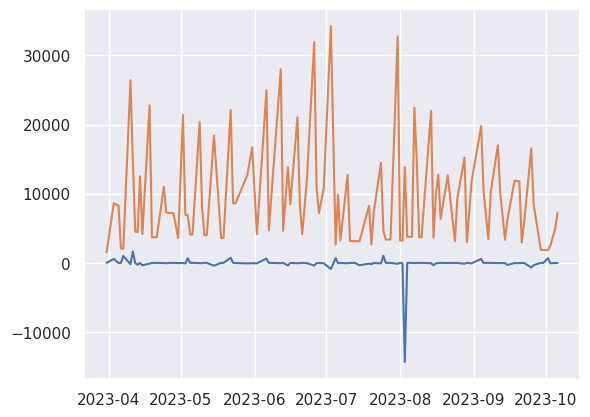

In [122]:

import matplotlib.pyplot as plt

# fishing for outliers

operations['date_operation'] = pd.to_datetime(operations['date_operation'], format='%Y-%m-%d')

montantPlot = operations.groupby('date_operation')['montant'].sum()
montantPlot = montantPlot.reset_index(drop=False)

soldePlot = operations.groupby('date_operation')['solde_avt_ope'].sum()
soldePlot = soldePlot.reset_index(drop=False)

plt.plot(montantPlot['date_operation'], montantPlot['montant'])
plt.plot(soldePlot['date_operation'], soldePlot['solde_avt_ope'])



In [123]:
print(operations['montant'].mean())
print(operations['montant'].median())
print(operations['montant'].quantile([0.25, 0.75]))

# most expenses remain within [2000, -2000] so let's check beneath that

operations.loc[operations['montant'] < -2000]

-45.73957928802589
-9.6
0.25   -20.59
0.75    -2.72
Name: montant, dtype: float64


,date_operation,libelle,montant,solde_avt_ope,categ
199,2023-08-03,CARTE XX XX XX XX,-15000.0,3797.35,AUTRE


QUIZ NETTOYER UN JEU DE DONNEES

In [124]:
course = pd.read_csv('/content/drive/MyDrive/Colab Notebooks & Co./course+-+Quiz+P2-V2(1).csv')
display(course.head())
print(course.columns)

,Position,Sexe,Temps,Dept,Temps_secondes,Age
0,1,M,00:32:23,76,1943,40.0
1,2,M,00:32:40,27,1960,34.0
2,3,M,00:33:15,76,1995,44.0
3,4,M,00:33:23,76,2003,46.0
4,5,M,00:33:29,76,2009,26.0


Index(['Position', 'Sexe', 'Temps', 'Dept', 'Temps_secondes', 'Age'], dtype='object')


In [125]:

display(course.loc[course['Dept'] != 76])
display(course.loc[course['Dept'] != 27])
display(course.loc[ course['Dept'] != 14])

,Position,Sexe,Temps,Dept,Temps_secondes,Age
1,2,M,00:32:40,27,1960,34.0
7,8,M,00:33:41,27,2021,37.0
10,11,M,00:34:20,14,2060,30.0
16,17,M,00:35:12,27,2112,52.0
18,19,M,00:36:12,27,2172,59.0
...,...,...,...,...,...,...
332,333,F,01:06:58,14,4018,29.0
335,336,F,01:08:34,27,4114,41.0
336,337,F,01:08:36,27,4116,48.0
337,338,M,01:09:31,27,4171,24.0


,Position,Sexe,Temps,Dept,Temps_secondes,Age
0,1,M,00:32:23,76,1943,40.0
2,3,M,00:33:15,76,1995,44.0
3,4,M,00:33:23,76,2003,46.0
4,5,M,00:33:29,76,2009,26.0
5,6,M,00:33:34,76,2014,22.0
...,...,...,...,...,...,...
331,332,F,01:06:54,14,4014,26.0
332,333,F,01:06:58,14,4018,29.0
333,334,F,01:08:07,76,4087,43.0
334,335,F,01:08:29,76,4109,32.0


,Position,Sexe,Temps,Dept,Temps_secondes,Age
0,1,M,00:32:23,76,1943,40.0
1,2,M,00:32:40,27,1960,34.0
2,3,M,00:33:15,76,1995,44.0
3,4,M,00:33:23,76,2003,46.0
4,5,M,00:33:29,76,2009,26.0
...,...,...,...,...,...,...
335,336,F,01:08:34,27,4114,41.0
336,337,F,01:08:36,27,4116,48.0
337,338,M,01:09:31,27,4171,24.0
338,339,F,01:09:31,27,4171,25.0


In [126]:
# trouver le département intrus
deptValides = [76, 27, 14]
courseDeptMask = ~course['Dept'].isin(deptValides)
course.loc[courseDeptMask]

,Position,Sexe,Temps,Dept,Temps_secondes,Age
21,22,M,00:36:22,78,2182,40.0
35,36,M,00:37:31,78,2251,42.0
74,75,M,00:42:06,78,2526,57.0
255,256,M,00:55:08,78,3308,42.0
289,290,F,00:59:09,78,3549,43.0


In [127]:
# valeurs manquantes
display(course.isnull().sum())

,0
Position,0
Sexe,2
Temps,0
Dept,0
Temps_secondes,0
Age,4


In [128]:

display(course.iloc[250, :])

# formattage de la variable 'temps'
course['Temps'] = pd.to_datetime(course['Temps'], format='%H:%M:%S', errors='coerce').dt.time
display(course)

# looking for a missing 'Temps' value
display(course[course['Temps'].isnull()])


,250
Position,251
Sexe,M
Temps,54min47s
Dept,27
Temps_secondes,0
Age,42.0


,Position,Sexe,Temps,Dept,Temps_secondes,Age
0,1,M,00:32:23,76,1943,40.0
1,2,M,00:32:40,27,1960,34.0
2,3,M,00:33:15,76,1995,44.0
3,4,M,00:33:23,76,2003,46.0
4,5,M,00:33:29,76,2009,26.0
...,...,...,...,...,...,...
335,336,F,01:08:34,27,4114,41.0
336,337,F,01:08:36,27,4116,48.0
337,338,M,01:09:31,27,4171,24.0
338,339,F,01:09:31,27,4171,25.0


,Position,Sexe,Temps,Dept,Temps_secondes,Age
250,251,M,NaT,27,0,42.0


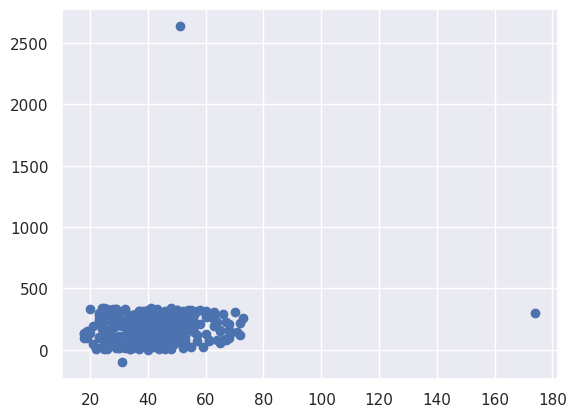

In [129]:
# quête d'outliers

plt.scatter(course['Age'], course['Position'])

In [130]:
course.loc[course['Temps'].duplicated(keep=False), :]

,Position,Sexe,Temps,Dept,Temps_secondes,Age
28,29,M,00:37:07,76,2227,31.0
29,30,M,00:37:07,76,2227,25.0
57,58,M,00:40:41,76,2441,65.0
58,59,M,00:40:41,27,2441,42.0
62,63,M,00:41:13,76,2473,53.0
...,...,...,...,...,...,...
328,329,F,01:06:07,27,3967,20.0
329,330,F,01:06:07,27,3967,28.0
330,331,F,01:06:07,27,3967,29.0
337,338,M,01:09:31,27,4171,24.0


In [131]:
# vérification d'erreurs sur la colonne sexe
sexeValides = ['M', 'F']
courseSexMask = ~course['Sexe'].isin(sexeValides)
courseSexMask.value_counts()

,count
Sexe,
False,336
True,4


In [132]:
# affichage des lignes concernées
course.loc[courseSexMask]

,Position,Sexe,Temps,Dept,Temps_secondes,Age
93,94,O,00:43:46,76,2626,18.0
109,110,NaN,00:44:39,27,2679,53.0
167,168,O,00:48:53,76,2933,24.0
291,292,NaN,00:59:16,27,3556,66.0


DISTRIBUTION EMPIRIQUE_VARIABLES QUALITATVES

In [133]:
operations = pd.read_csv('/content/drive/MyDrive/Colab Notebooks & Co./operations_corrigé.csv')
display(operations.head())

,date_operation,libelle,montant,solde_avt_ope,categ
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE


In [134]:
opeDistCat = operations['categ'].value_counts()
opeDistCat = opeDistCat.reset_index(drop=False)
opeDistCat['fréquence'] = opeDistCat['count']/operations.shape[0]
opeDistCat.columns = ['modalité', 'effectif', 'fréquence' ]
display(opeDistCat)





,modalité,effectif,fréquence
0,AUTRE,212,0.686084
1,COURSES,40,0.129450
2,TRANSPORT,21,0.067961
3,RESTAURANT,16,0.051780
4,COTISATION BANCAIRE,7,0.022654
5,FACTURE TELEPHONE,6,0.019417
6,LOYER,6,0.019417


([<matplotlib.patches.Wedge at 0x79e1c777b500>,
 [Text(-0.6134575858006734, 0.9130551957157955, 'AUTRE'),
  Text(0.022438508730269306, -1.0997711186087593, 'COURSES'),
  Text(0.6592055596137661, -0.8805952703565365, 'TRANSPORT'),
  Text(0.9373174474443177, -0.5757047878179135, 'RESTAURANT'),
  Text(1.0454666044596066, -0.34205201206790226, 'COTISATION BANCAIRE'),
  Text(1.0815121390366498, -0.20082702287384122, 'FACTURE TELEPHONE'),
  Text(1.0979406851809932, -0.06727742432860624, 'LOYER')])

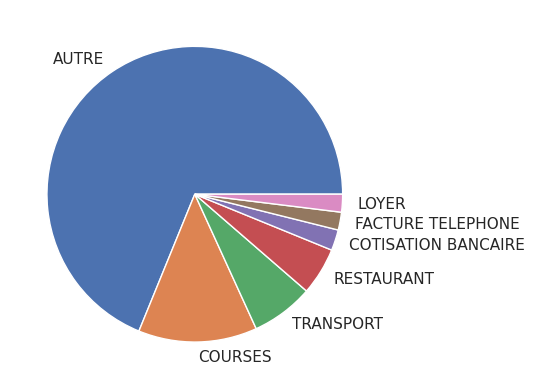

In [135]:
sns.set_theme()
plt.pie(x=opeDistCat['effectif'], labels=opeDistCat['modalité'])


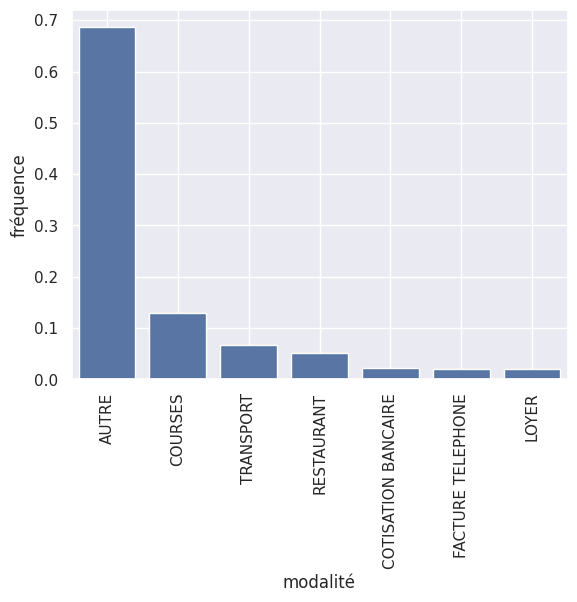

In [136]:
sns.set_theme()
sns.barplot(x=opeDistCat['modalité'], y=opeDistCat['fréquence'] )
plt.xticks(rotation='vertical')
plt.grid('both')


DISTRIBUTION EMPIRIQUE_VARIABLES QUANTITATIVES

In [137]:
display(operations.head())

,date_operation,libelle,montant,solde_avt_ope,categ
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE


<Axes: xlabel='quart_mois'>

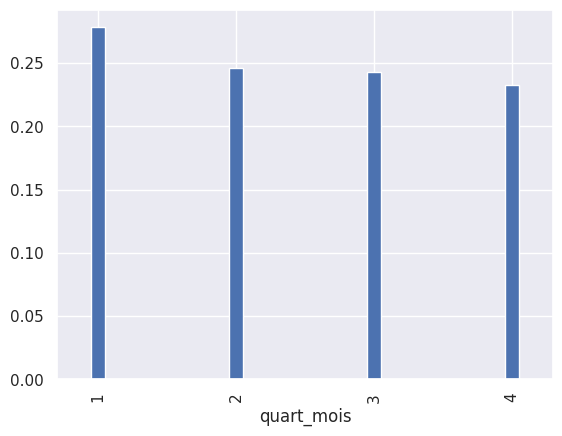

In [138]:
# création d'une colonne type date avec le données de la colonne d'origine (objet)
operations['date_operation'] = pd.to_datetime(operations['date_operation'])
# transformation des dates des colonnes en un chiffre (1, 2, 3, 4) en fonction de leur quart de mois:
  # (jour-1) fait en sorte que toutes les dates soient entre 0 et 30
  # *4 because we need 4 quarters
  # /31 because march has 31 days
  # the series data would be numbers between 0 and 3.87
  # int() transforms a float to an integer by strightout dropping the decimal part
  # the series data would be 0, 1, 2 or 3
  # +1 adds to each value of the series (1, 2, 3, 4)
  # the loop says "for each value on the list in this date format apply the precedent formula"
operations['quart_mois'] = [int((jour-1)*4/31)+1 for jour in operations['date_operation'].dt.day]
# request a bar plot with a normalized count of the series to visualize the expenses proportion of each quart of the month
operations['quart_mois'].value_counts(normalize=True).plot(kind='bar', width=0.1)

In [139]:
operations['date_operation'] = pd.to_datetime(operations['date_operation'])


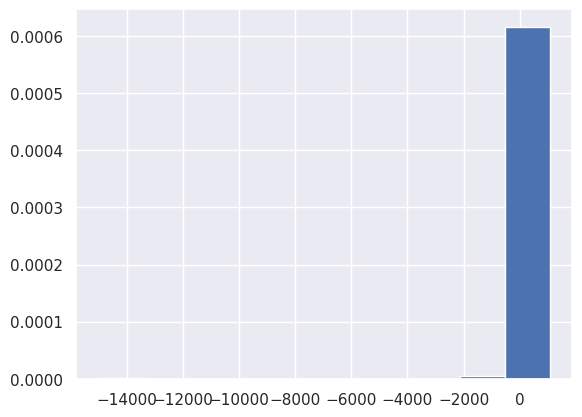

In [140]:
# pour créer un histogramme à partir des données quantitatives discrètes:
  # on crée des intervalles denominés classes qui peuvent être de taille différente
  # la méthode .hist() s'occupe de regrouper les valeurs en classes
operations['montant'].hist(density=True)
plt.show()


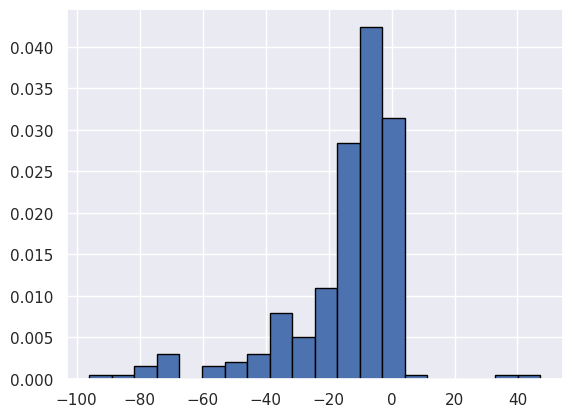

In [141]:

# pour obtenir un histogramme moins étalé:
  # on séléctionne les opérations de la colonne montant dont le montant absolu est en dessous de 100
  # on demande un histogramme alors de la colonne montant uniquement
    #spécifiant qu'on veut afficher des proportions, pas les compte, et un total de 20 classes
operations[operations.montant.abs() < 100]['montant'].hist(density=True, bins=20, edgecolor='black')
plt.show()

VARIABLES SOUS FORME DE TABLEAU - VARIABLES QUANTITATIVES DISCRETES

In [142]:
# Récupérer la nouvelle série que nous avons discrétisées, pour rappel:
operations['quart_mois'] = [int((jour-1)*4/31)+1 for jour in operations['date_operation'].dt.day]
display(operations['quart_mois'])

,quart_mois
0,4
1,1
2,1
3,1
4,1
...,...
304,1
305,1
306,1
307,1


In [143]:
# Créer une nouvelle variable avec le compte des valeurs uniques de la série (les effectifs)
operationsEff = operations['quart_mois'].value_counts()
display(operationsEff)
# Extraction de l'index et en créer une variable également (les modalités)
operationsMod = operationsEff.index
display(operationsMod)

,count
quart_mois,
1,86
2,76
3,75
4,72


Index([1, 2, 3, 4], dtype='int64', name='quart_mois')

In [144]:
# Création d'un nouveau data frame initialisé avec les modalités
operationsFreq = pd.DataFrame(operationsMod, columns = ['quart_mois'])
display(operationsFreq)

,quart_mois
0,1
1,2
2,3
3,4


In [145]:
# Création of a column 'n' with JUST the VALUES of the series with the counts
operationsFreq['n'] = operationsEff.values
display(operationsFreq)

,quart_mois,n
0,1,86
1,2,76
2,3,75
3,4,72


In [146]:
# Ajout d'une nouvelle série avec le calcul des fréquences sur le total de lignes du DaatFrame d'origine
operationsFreq['f'] = operationsFreq['n']/operations.shape[0]
display(operationsFreq)

,quart_mois,n,f
0,1,86,0.278317
1,2,76,0.245955
2,3,75,0.242718
3,4,72,0.233010


In [147]:
# Trier le tableau selon la série quart_mois
operationsFreq = operationsFreq.sort_values('quart_mois')
# Ajout d'une nouvelle série avec le calcul cumulatif de colonne des fréquences
operationsFreq['F'] = operationsFreq['f'].cumsum()
display(operationsFreq)

,quart_mois,n,f,F
0,1,86,0.278317,0.278317
1,2,76,0.245955,0.524272
2,3,75,0.242718,0.766990
3,4,72,0.233010,1.000000


VARIABLES SOUS FORME DE TABLEAU - VARIABLES QUALITATIVES

In [148]:
operationsCategCount = operations['categ'].value_counts()
operationsCategMod = operationsCategCount.index
operationsCateg = pd.DataFrame({'categ': operationsCategMod})
operationsCateg['n'] = operationsCategCount.values
operationsCateg['f'] = operationsCateg['n']/ operations.shape[0]
display(operationsCateg)

,categ,n,f
0,AUTRE,212,0.686084
1,COURSES,40,0.129450
2,TRANSPORT,21,0.067961
3,RESTAURANT,16,0.051780
4,COTISATION BANCAIRE,7,0.022654
5,FACTURE TELEPHONE,6,0.019417
6,LOYER,6,0.019417


VARIABLES SOUS FORME DE TABLEAU - VARIABLES QUANTITATIVES CONTINUES

In [149]:
# création d'une liste de limites qui deviendront des intervalles
operationsMontantInt = [-120, -90, -60, -30, 0, 30, 60, 90, 120]
display(operationsMontantInt)


[-120, -90, -60, -30, 0, 30, 60, 90, 120]

In [150]:
# création d'une série composée des intervales de la liste
operationsMontantInt = pd.cut(operations['montant'], bins=operationsMontantInt, right=True)
display(operationsMontantInt)

,montant
0,"(-30.0, 0.0]"
1,"(-30.0, 0.0]"
2,"(-90.0, -60.0]"
3,NaN
4,"(0.0, 30.0]"
...,...
304,"(-30.0, 0.0]"
305,"(-30.0, 0.0]"
306,"(-30.0, 0.0]"
307,"(-30.0, 0.0]"


In [151]:
# compter l'effectif des valeurs uniques de notre série puis les ordonner selon l'index (les intervales)
# la discrétisation est complète
operationsMontantEff = operationsMontantInt.value_counts().sort_index()
display(operationsMontantEff )

,count
montant,
"(-120, -90]",2
"(-90, -60]",11
"(-60, -30]",29
"(-30, 0]",234
"(0, 30]",3
"(30, 60]",2
"(60, 90]",0
"(90, 120]",0


In [152]:
# création du DataFrame à partir de .index et .values de la série
operationsMontant = pd.DataFrame({'montant': operationsMontantEff.index, 'n': operationsMontantEff.values})
display(operationsMontant)

,montant,n
0,"(-120, -90]",2
1,"(-90, -60]",11
2,"(-60, -30]",29
3,"(-30, 0]",234
4,"(0, 30]",3
5,"(30, 60]",2
6,"(60, 90]",0
7,"(90, 120]",0


In [153]:
# Ajout d'une nouvelle série avec le calcul des fréquences sur le total de lignes du DaatFrame d'origine
operationsMontant['f'] = operationsMontant['n']/operations.shape[0]
display(operationsMontant)

,montant,n,f
0,"(-120, -90]",2,0.006472
1,"(-90, -60]",11,0.035599
2,"(-60, -30]",29,0.093851
3,"(-30, 0]",234,0.757282
4,"(0, 30]",3,0.009709
5,"(30, 60]",2,0.006472
6,"(60, 90]",0,0.000000
7,"(90, 120]",0,0.000000


In [154]:
# Ajout d'une nouvelle série avec le calcul cumulatif de colonne des fréquences
operationsMontant['F'] = operationsMontant['f'].cumsum()
display(operationsMontant)

,montant,n,f,F
0,"(-120, -90]",2,0.006472,0.006472
1,"(-90, -60]",11,0.035599,0.042071
2,"(-60, -30]",29,0.093851,0.135922
3,"(-30, 0]",234,0.757282,0.893204
4,"(0, 30]",3,0.009709,0.902913
5,"(30, 60]",2,0.006472,0.909385
6,"(60, 90]",0,0.000000,0.909385
7,"(90, 120]",0,0.000000,0.909385


STATISTIQUES BASIQUES

In [155]:
display(operations.head())

,date_operation,libelle,montant,solde_avt_ope,categ,quart_mois
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE,4
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT,1
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT,1
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE,1
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE,1


In [156]:
# le mode d'une série
operations['montant'].mode()

,montant
0,-1.6


In [157]:
# le moyenne d'une série
operations['montant'].mean()

np.float64(-45.911889250814326)

In [158]:
# la médiane d'une série
operations['montant'].median()

-9.6

In [159]:


for cat, group in operations.groupby('categ'):
  print('Mode', cat, group['montant'].mode())
  print('Moyenne', cat, group['montant'].mean())
  print('Médiane', cat, group['montant'].median())


  print(' ')


Mode AUTRE 0   -1.6
Name: montant, dtype: float64
Moyenne AUTRE -47.42071090047393
Médiane AUTRE -8.14
 
Mode COTISATION BANCAIRE 0   -1.92
Name: montant, dtype: float64
Moyenne COTISATION BANCAIRE -1.8857142857142857
Médiane COTISATION BANCAIRE -1.92
 
Mode COURSES 0   -32.67
Name: montant, dtype: float64
Moyenne COURSES -16.497435897435896
Médiane COURSES -12.24
 
Mode FACTURE TELEPHONE 0   -7.02
1   -6.38
Name: montant, dtype: float64
Moyenne FACTURE TELEPHONE -7.973333333333333
Médiane FACTURE TELEPHONE -7.02
 
Mode LOYER 0   -345.0
Name: montant, dtype: float64
Moyenne LOYER -345.0
Médiane LOYER -345.0
 
Mode RESTAURANT 0   -9.2
Name: montant, dtype: float64
Moyenne RESTAURANT -10.3325
Médiane RESTAURANT -10.1
 
Mode TRANSPORT 0   -73.0
Name: montant, dtype: float64
Moyenne TRANSPORT -52.99714285714286
Médiane TRANSPORT -53.1
 


MESURES DE DISPERSION

In [160]:
# calculer la variance empirique autour de la moyenne
operations['montant'].var()

764296.6351545885

In [161]:
# calculer la variance empirique autour de la moyenne sans biais
operations['montant'].var(ddof=1)

764296.6351545885

In [162]:
# calculer l'écart type empirique (la racine carrée de la variance empirique)
operations['montant'].std()

874.2406048420472

In [163]:
# le coefficient de variation (CV) nous permet de
# mettre un nombre sur la proportionalité entre l'écart type et la moyenne de l'échantillon
operations['montant'].std()/operations['montant'].mean()

np.float64(-19.041703992317004)

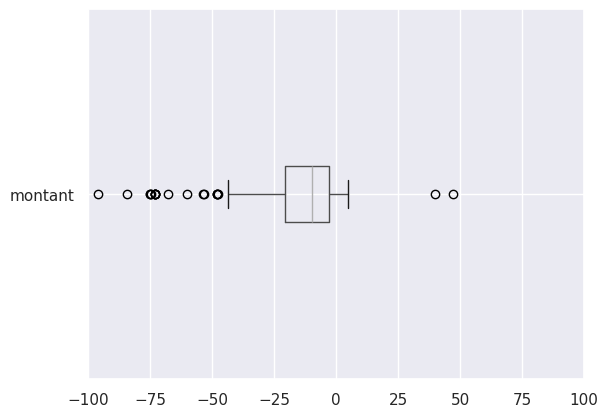

In [164]:
# création d'une boîte à moustaches à partir d'une série
operations.boxplot(column='montant', vert=False)
plt.xlim(-100, 100)
plt.show()

In [165]:
# moyenne par catégories
moyenneCat = round(operations.groupby('categ')['montant'].mean(), 2)
print('La moyenne par catégories est de',moyenneCat,'.')
# écart-type par catégories
ecartCat = round(operations.groupby('categ')['montant'].std(), 2)
print("L'écart type par catégories est de", ecartCat,'.')
# variance par catégories
varCat = round(operations.groupby('categ')['montant'].var(), 2)
print('La variance par catégorie est de', varCat, '.')

La moyenne par catégories est de categ
AUTRE                  -47.42
COTISATION BANCAIRE     -1.89
COURSES                -16.50
FACTURE TELEPHONE       -7.97
LOYER                 -345.00
RESTAURANT             -10.33
TRANSPORT              -53.00
Name: montant, dtype: float64 .
L'écart type par catégories est de categ
AUTRE                  1053.81
COTISATION BANCAIRE       0.04
COURSES                  13.64
FACTURE TELEPHONE         2.78
LOYER                     0.00
RESTAURANT                1.74
TRANSPORT                48.12
Name: montant, dtype: float64 .
La variance par catégorie est de categ
AUTRE                  1110508.42
COTISATION BANCAIRE          0.00
COURSES                    185.92
FACTURE TELEPHONE            7.72
LOYER                        0.00
RESTAURANT                   3.04
TRANSPORT                 2315.27
Name: montant, dtype: float64 .


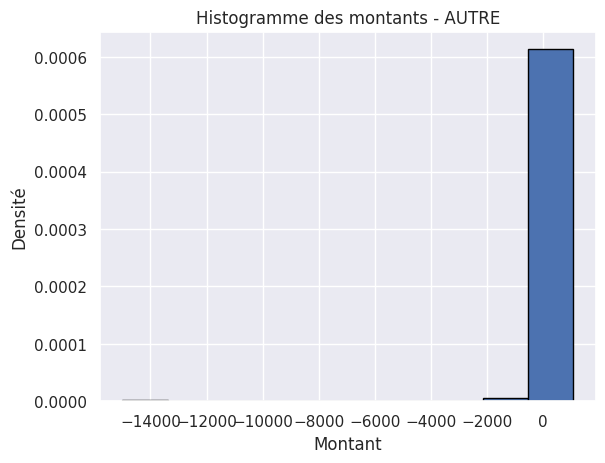

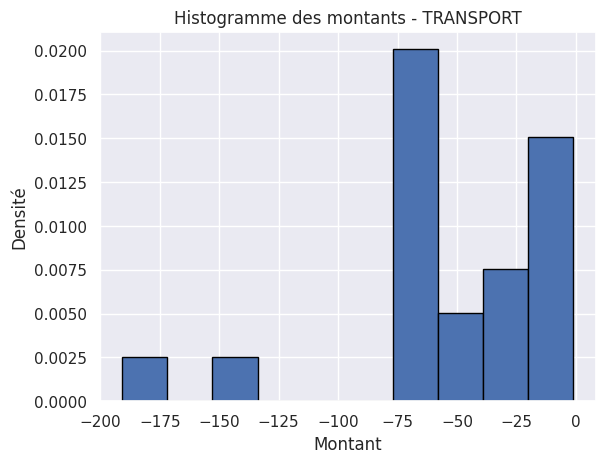

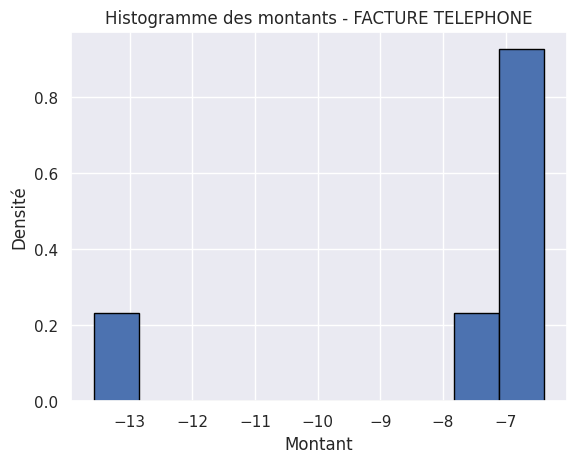

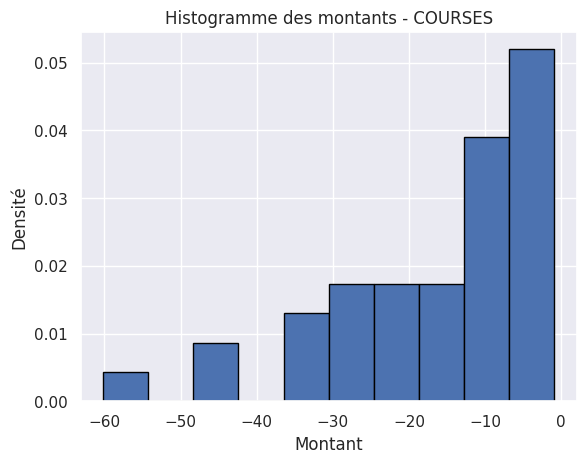

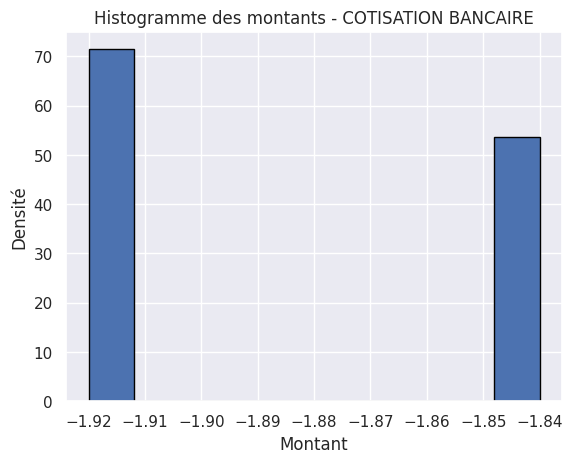

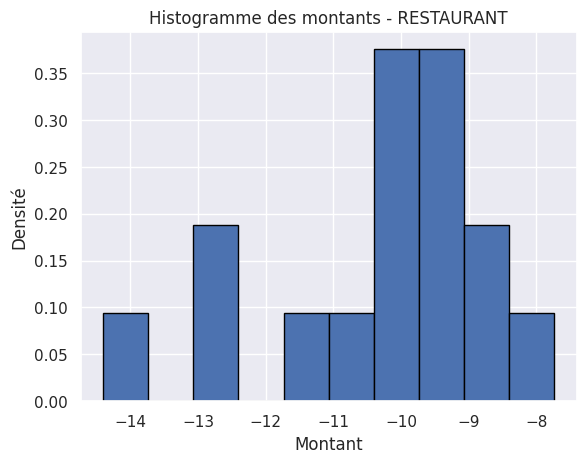

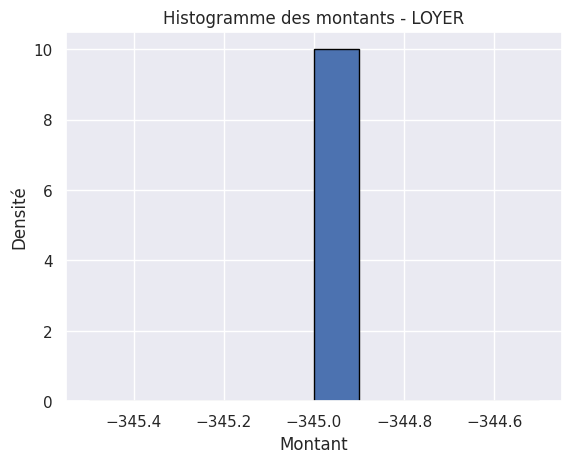

/usr/local/lib/python3.12/dist-packages/numpy/lib/_histograms_impl.py:895: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


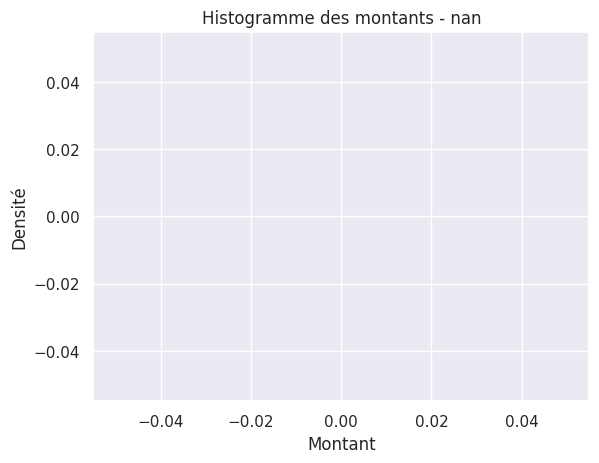

In [166]:
# boucle qui parcourt les valeurs uniques de la série 'categ'
for cat in operations['categ'].unique():
  plt.figure() # makes sure the histograms are separated
  # creation of a new variable that stores the values of the 'montant' series that match the unique value of the 'categ' series
  categ = operations[operations['categ'] == cat]['montant']
  categ.hist(density=True, edgecolor='black')
  plt.title(f"Histogramme des montants - {cat}")
  plt.xlabel('Montant')
  plt.ylabel('Densité')
  plt.show()

<Figure size 640x480 with 0 Axes>

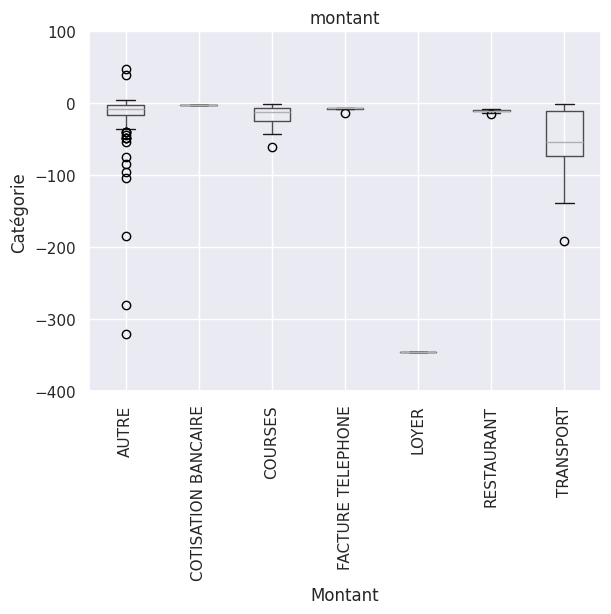

In [167]:
plt.figure()
operations.boxplot(column='montant', by='categ')
plt.suptitle('')
plt.xlabel('Montant')
plt.ylabel('Catégorie')
plt.xticks(rotation='vertical')
plt.ylim(-400, 100)
plt.show()

In [168]:
transport = operations[operations['categ'] == 'TRANSPORT']['montant']
meanTransport = transport.sum()/len(transport)
varTransport = ((transport - meanTransport)**2).sum()/(len(transport)-1)
stdTransport = varTransport**0.5
display(transport)
display(round(meanTransport))
display(round(varTransport))
display(round(stdTransport))

,montant
1,-24.00
2,-73.00
20,-2.70
36,-1.70
56,-73.00
83,-138.24
95,-73.00
120,-29.00
141,-23.85
149,-73.00


-53

2315

48

In [169]:
autre = operations[operations['categ'] == 'AUTRE']['montant']
autre.mean()

np.float64(-47.42071090047393)

In [170]:
autre.std()

1053.8066339875447

In [171]:
bigExpenses = operations[(operations['montant'] > -100) & (operations['categ'] == 'AUTRE') ]
display(bigExpenses)

,date_operation,libelle,montant,solde_avt_ope,categ,quart_mois
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE,4
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE,1
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE,1
5,2023-04-03,CARTE XX XX XX XX,-14.39,2097.61,AUTRE,1
6,2023-04-05,CARTE XX XX XX XX XX,-15.20,2083.22,AUTRE,1
...,...,...,...,...,...,...
300,2023-09-29,DON XX XX XX XX XX XX XX,-1.76,1870.38,AUTRE,4
301,2023-09-30,XX XX VIREMENT XX XX XX,-36.00,1868.62,AUTRE,4
302,2023-10-02,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1832.62,AUTRE,1
304,2023-10-05,CARTE XX XX XX XX XX XX,-10.64,2440.94,AUTRE,1


In [172]:
bigAutre = operations[(operations ['montant'] < -200) & (operations['categ'] == 'AUTRE')]
display(bigAutre)

,date_operation,libelle,montant,solde_avt_ope,categ,quart_mois
26,2023-04-13,XX XX XX XX XX XX XX,-280.00,4461.50,AUTRE,2
153,2023-07-03,CARTE XX XX XX XX XX XX XX XX,-602.27,3236.57,AUTRE,1
199,2023-08-03,CARTE XX XX XX XX,-15000.00,3797.35,AUTRE,1
289,2023-09-25,PRELEVEMENT XX XX XX XX XX XX XX XX,-593.60,2898.75,AUTRE,4
298,2023-09-26,RETRAIT XX XX XX,-320.00,2191.58,AUTRE,4


In [173]:
restauTrans = operations[(operations['categ'] == 'RESTAURANT') | (operations['categ'] == 'TRANSPORT')]
display(restauTrans)

,date_operation,libelle,montant,solde_avt_ope,categ,quart_mois
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT,1
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT,1
15,2023-04-10,CARTE XX XX CHEZ LUC XX,-12.42,2926.36,RESTAURANT,2
20,2023-04-10,CARTE XX XX VELOC XX XX,-2.70,2843.28,TRANSPORT,2
28,2023-04-14,CARTE XX XX CHEZ LUC XX,-8.80,4179.90,RESTAURANT,2
36,2023-04-18,CARTE XX XX VELOC XX XX,-1.70,3709.28,TRANSPORT,3
42,2023-04-24,CARTE XX XX CHEZ LUC XX,-9.20,3656.87,RESTAURANT,3
56,2023-05-03,CARTE XX XX RAPT XX,-73.00,3523.97,TRANSPORT,1
67,2023-05-10,CARTE XX XX CHEZ LUC XX,-9.60,4046.92,RESTAURANT,2
73,2023-05-15,CARTE XX XX CHEZ LUC XX,-11.00,3609.12,RESTAURANT,2


In [174]:
smallExpenses = operations[(operations['montant'] < 0) & (operations['montant'] > -50)]
display(smallExpenses)

,date_operation,libelle,montant,solde_avt_ope,categ,quart_mois
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE,4
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT,1
5,2023-04-03,CARTE XX XX XX XX,-14.39,2097.61,AUTRE,1
6,2023-04-05,CARTE XX XX XX XX XX,-15.20,2083.22,AUTRE,1
7,2023-04-05,CARTE XX XX XX XX,-12.00,2068.02,AUTRE,1
...,...,...,...,...,...,...
304,2023-10-05,CARTE XX XX XX XX XX XX,-10.64,2440.94,AUTRE,1
305,2023-10-05,CARTE XX XX XX XX,-4.80,2430.30,AUTRE,1
306,2023-10-06,FORFAIT COMPTE SUPERBANK XX XX XX XX,-1.92,2425.50,COTISATION BANCAIRE,1
307,2023-10-06,CARTE XX XX CHEZ LUC XX,-10.00,2423.58,RESTAURANT,1


In [175]:
restaurant = operations[operations['categ'] == 'RESTAURANT']['montant']
restaurantMean = restaurant.sum()/len(restaurant)
restaurantVar = (((restaurant-restaurantMean) **2).sum())/len(restaurant) -1
restaurantStd = restaurantVar **0.5

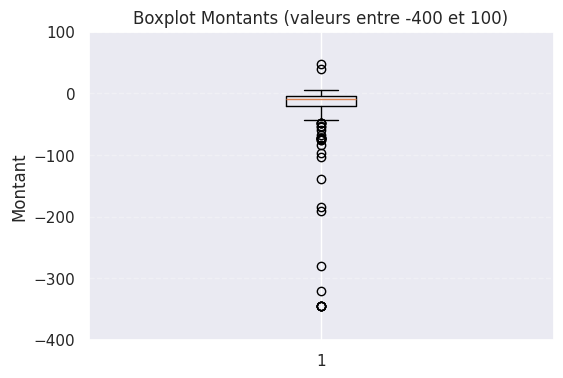

In [176]:

# outliers need to be filtered out using masks to allow the boxplot to actually show
montant_vis = operations.loc[(operations['montant'] > -400) & (operations['montant'] < 100), 'montant']

plt.figure(figsize=(6, 4))
plt.boxplot(montant_vis, vert=True)
plt.ylabel('Montant')
plt.title('Boxplot Montants (valeurs entre -400 et 100)')
plt.ylim(-400, 100)
plt.grid(True, axis='y', linestyle='--', alpha=0.3)
plt.show()

In [177]:
# Calculer le skewness empirique
operations['montant'].skew()

np.float64(-16.42821460420292)

In [178]:
# Calculer la kurtosis empirique
operations['montant'].kurtosis()

np.float64(282.31637060086683)

In [179]:
operationsSkew = operations.groupby('categ')['montant'].skew()
display(operationsSkew)

,montant
categ,
AUTRE,-13.703829
COTISATION BANCAIRE,0.374166
COURSES,-1.204093
FACTURE TELEPHONE,-2.326285
LOYER,0.000000
RESTAURANT,-0.888350
TRANSPORT,-1.248265


 
AUTRE
moy:
 -47.42071090047393
med:
 -8.14
mod:
 0   -1.6
Name: montant, dtype: float64
var:
 1105245.348746888
std:
 1051.3064961022965
skew:
 -13.703828821717531
kurt:
 195.59900832269122


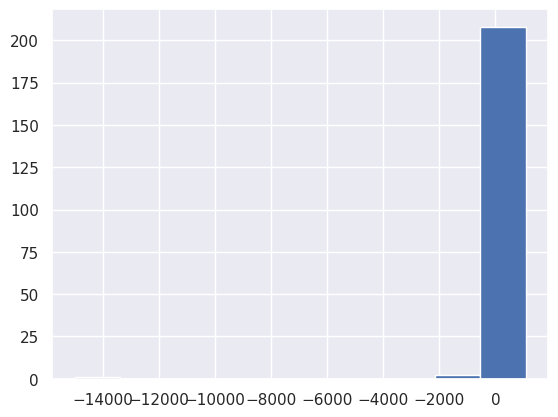

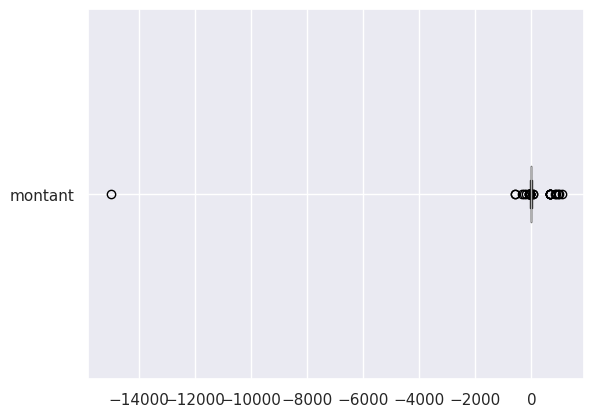

 
TRANSPORT
moy:
 -52.99714285714286
med:
 -53.1
mod:
 0   -73.0
Name: montant, dtype: float64
var:
 2205.016868027212
std:
 46.95760713694014
skew:
 -1.248265076217821
kurt:
 2.1922705326917495


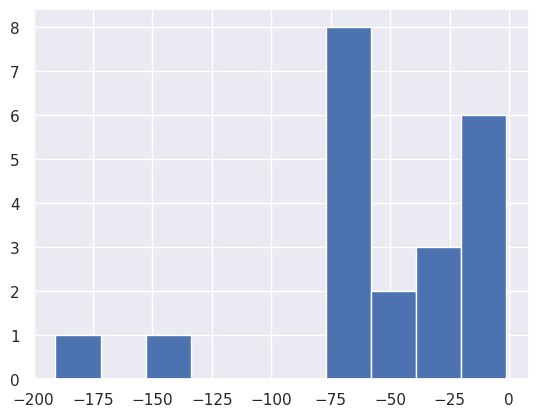

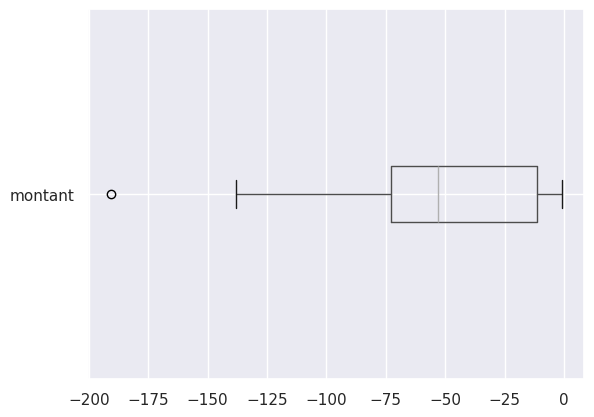

 
FACTURE TELEPHONE
moy:
 -7.973333333333333
med:
 -7.02
mod:
 0   -7.02
1   -6.38
Name: montant, dtype: float64
var:
 6.432222222222222
std:
 2.536182608216968
skew:
 -2.3262852094198623
kurt:
 5.531681192471323


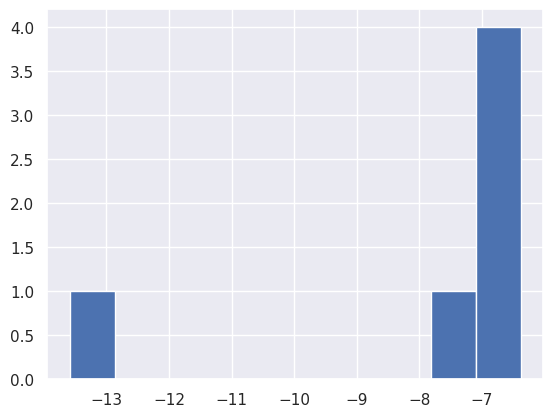

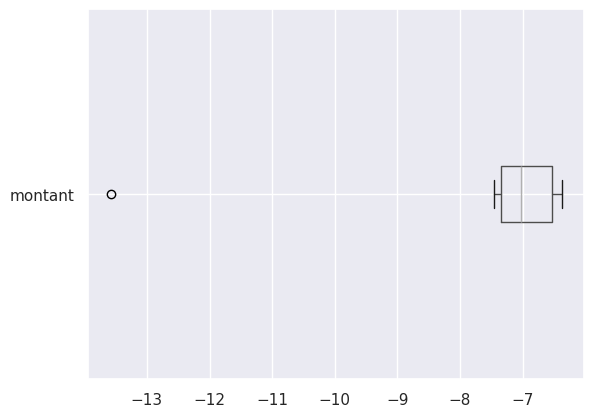

 
COURSES
moy:
 -16.497435897435896
med:
 -12.24
mod:
 0   -32.67
Name: montant, dtype: float64
var:
 181.14957804076266
std:
 13.4591819231617
skew:
 -1.2040932608409276
kurt:
 1.3774708176939345


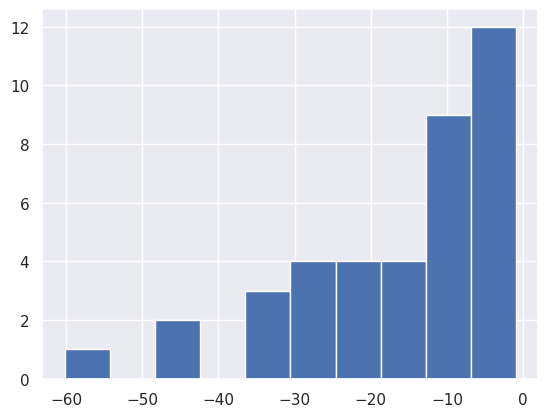

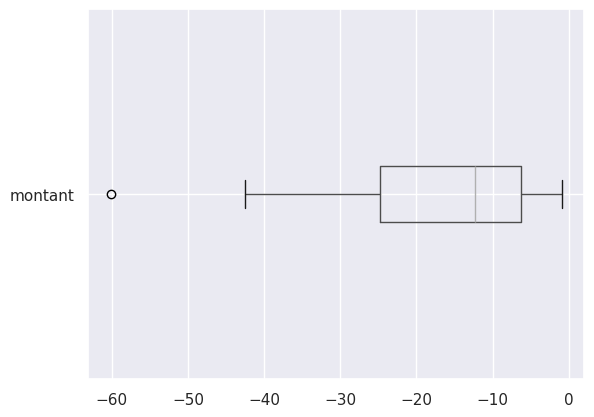

 
COTISATION BANCAIRE
moy:
 -1.8857142857142857
med:
 -1.92
mod:
 0   -1.92
Name: montant, dtype: float64
var:
 0.0015673469387755044
std:
 0.03958973274443141
skew:
 0.37416573867739106
kurt:
 -2.800000000000003


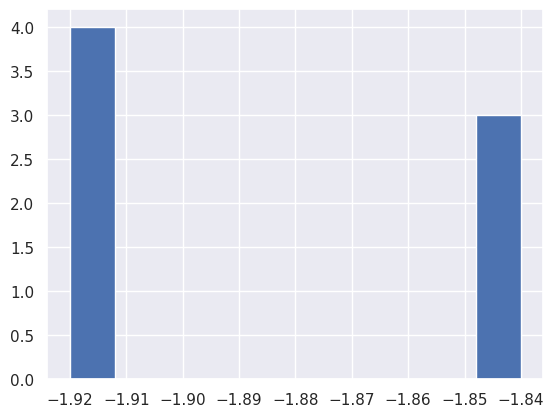

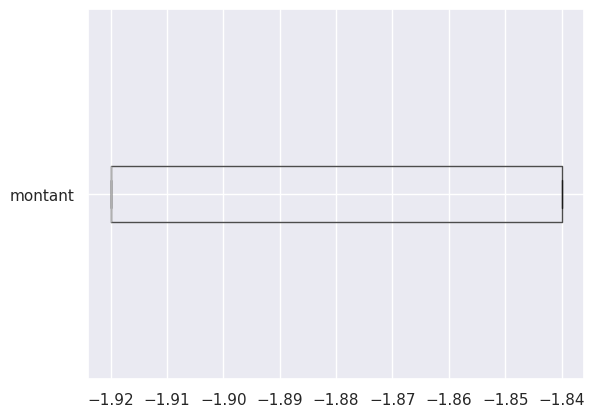

 
RESTAURANT
moy:
 -10.3325
med:
 -10.1
mod:
 0   -9.2
Name: montant, dtype: float64
var:
 2.853193750000001
std:
 1.689139943876765
skew:
 -0.8883503487158837
kurt:
 0.5988855591691937


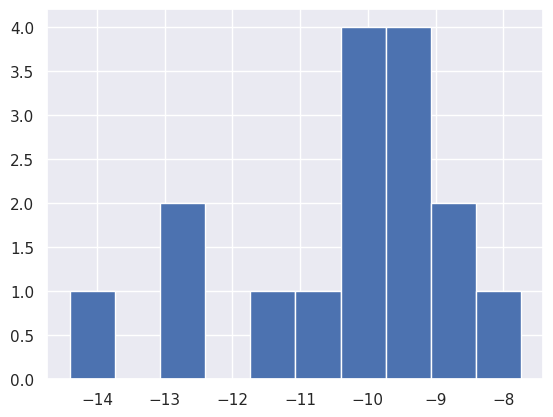

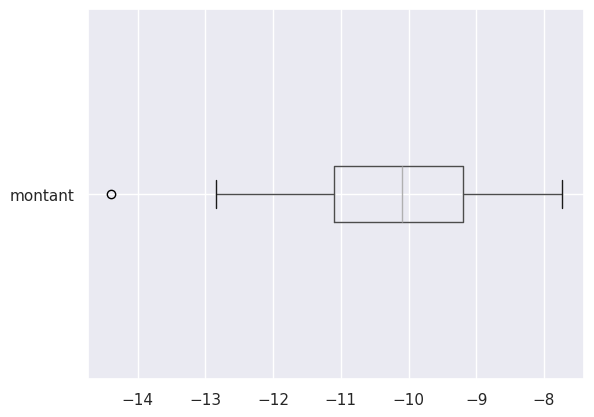

 
LOYER
moy:
 -345.0
med:
 -345.0
mod:
 0   -345.0
Name: montant, dtype: float64
var:
 0.0
std:
 0.0
skew:
 0.0
kurt:
 0.0


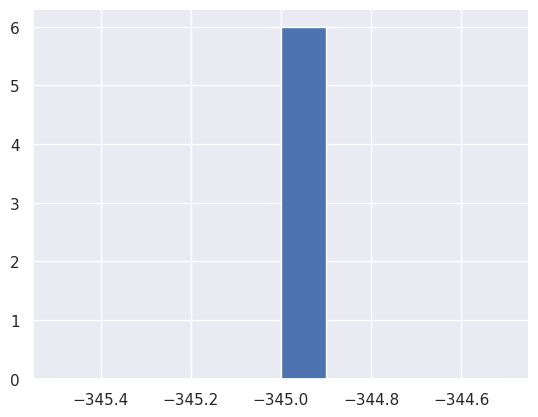

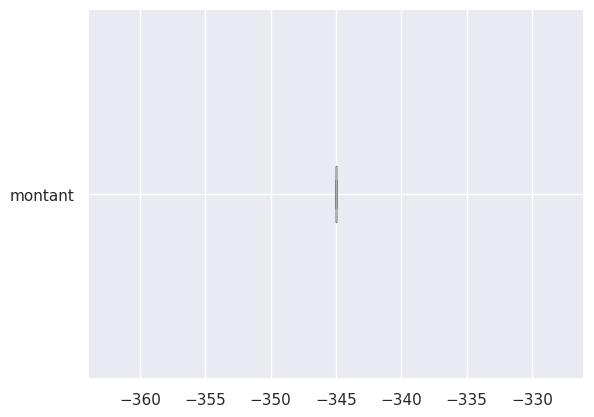

 
nan
moy:
 nan
med:
 nan
mod:
 Series([], Name: montant, dtype: float64)
var:
 nan
std:
 nan
skew:
 nan
kurt:
 nan


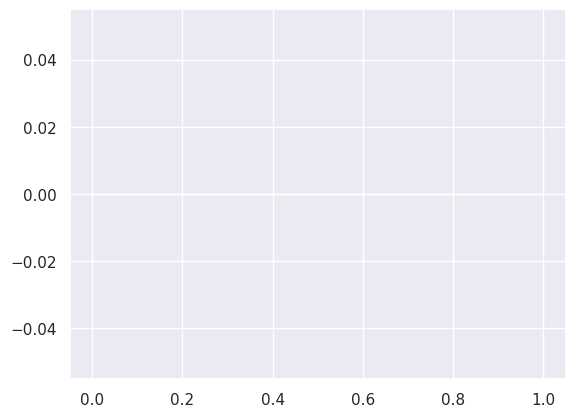

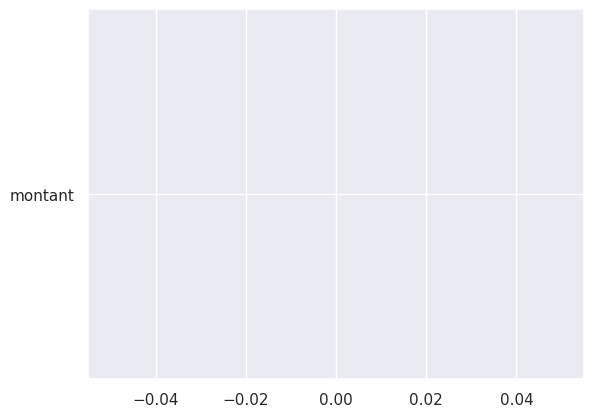

In [180]:
for cat in operations['categ'].unique():
  category = operations.loc[operations['categ'] == cat, :] # will generate a subset per category
  print(' ')
  print(cat)
  print('moy:\n', category['montant'].mean())
  print('med:\n', category['montant'].median())
  print('mod:\n', category['montant'].mode())
  print('var:\n', category['montant'].var(ddof=0))
  print('std:\n', category['montant'].std(ddof=0))
  print('skew:\n', category['montant'].skew())
  print('kurt:\n', category['montant'].kurt())
  category['montant'].hist()
  plt.show()
  category.boxplot(column='montant', vert=False)
  plt.show()

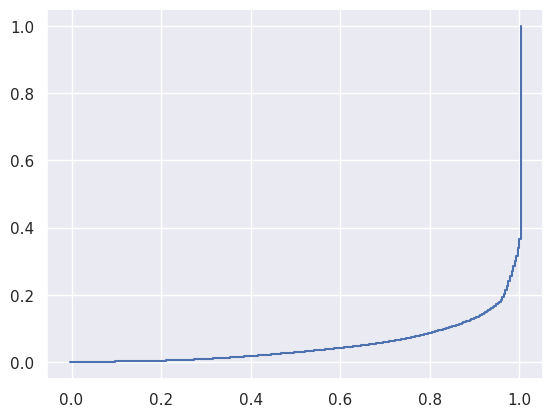

In [181]:
# pour afficher la courbe de Lorenz
# mask de toutes les dépénses
depenses = operations[operations['montant'] < 0]
# on récupère que les valeurs de la série montant
dep = -depenses['montant'].values
# on compte la quantité de lignes de dépenses
n = len(dep)

# on divise le cumul des valeurs des dépenses ordonnées par la somme de valeurs des dépenses
lorenz = np.cumsum(np.sort(dep)) / dep.sum()

lorenz = np.append([0], lorenz)

xaxis = np.linspace(0-1/n, 1+1/n, n+1)
plt.plot(xaxis, lorenz, drawstyle='steps-post')
plt.show()

# **ANALYSES BIVARIEES**

CORRELATION ENTRE VARIABLES QUANTITATIVES

In [182]:
display(operations.head())

,date_operation,libelle,montant,solde_avt_ope,categ,quart_mois
0,2023-03-31,DON XX XX XX XX XX XX XX,-1.44,1515.25,AUTRE,4
1,2023-04-03,CARTE XX XX RAPT XX,-24.00,1513.81,TRANSPORT,1
2,2023-04-03,CARTE XX XX RAPT XX,-73.00,1489.81,TRANSPORT,1
3,2023-04-03,VIREMENT XX XX XX XX XX XX XX XX XX XX XX XX,676.00,1416.81,AUTRE,1
4,2023-04-03,VIREMENT XX XX XX XX XX XX,4.80,2092.81,AUTRE,1


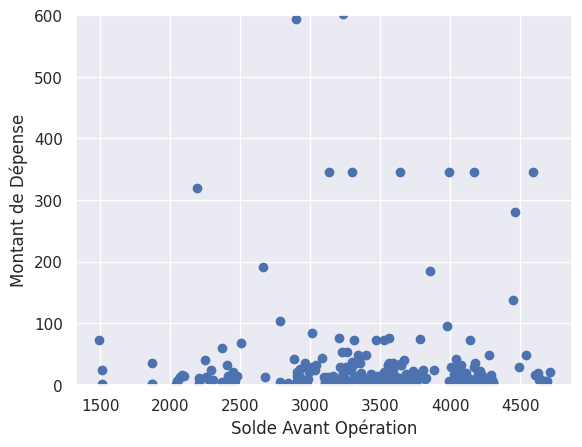

In [183]:
depenses = operations[operations.montant < 0] # masque des dépenses
sns.set_theme()
plt.plot(depenses['solde_avt_ope'], -depenses['montant'], 'o') # important de les marquer en négatif
plt.xlabel('Solde Avant Opération')
plt.ylabel('Montant de Dépense')
plt.ylim(0, 600)
plt.show()

In [184]:
tailleClasse = 500

groupes = []

tranches = np.arange(0, max(depenses['solde_avt_ope']), tailleClasse)
tranches += tailleClasse/2
indices = np.digitize(depenses['solde_avt_ope'], tranches)

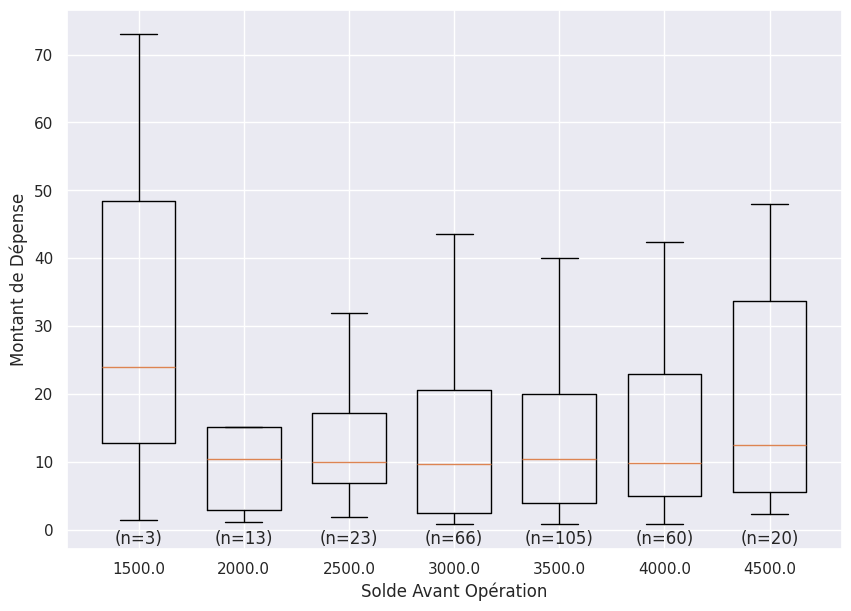

In [185]:
for ind, tr in enumerate(tranches):
  montants = -depenses.loc[indices==ind, 'montant']
  if len(montants) > 0:
    g = {'valeurs': montants, 'centre_classe' : tr-(tailleClasse/2),'taille': len(montants),'quartiles': [np.percentile(montants, p) for p in [25, 50, 75]]}
    groupes.append(g)

plt.figure(figsize=(10, 7))

plt.boxplot([g['valeurs'] for g in groupes], positions= [g['centre_classe'] for g in groupes], showfliers=False, widths= tailleClasse*0.7)

for g in groupes:
  plt.text(g['centre_classe'], 0, '(n={})'.format(g['taille']), horizontalalignment='center', verticalalignment='top')
plt.xlabel('Solde Avant Opération')
plt.ylabel('Montant de Dépense')
plt.show()

COEFFICIENT DE PEARSON ET COVARIANCE EMPIRIQUE

In [186]:
import scipy.stats as st

In [187]:
# calculer le coefficient de Pearson (coefficient de corrélation linéaire)
print(st.pearsonr(depenses['solde_avt_ope'], -depenses['montant'])[0])

0.03495679791618303


In [188]:
# calculer la covariance
print(np.cov(depenses['solde_avt_ope'], -depenses['montant'], ddof=0)[1, 0])

19929.942276393584


In [189]:
import datetime as dt

In [190]:
courses = operations[operations.categ == 'COURSES']
courses = courses.sort_values('date_operation')
courses['montant'] = -courses['montant']
r = []
last_date = dt.datetime.now()
for i, row in courses.iterrows():
  days = (row['date_operation'] - last_date).days
  if days == 0:
    r.append(r[-1])
  else:
    r.append(days)
  last_date = row['date_operation']
courses['attente'] = r
courses = courses.iloc[1: ,]

a = courses.groupby('date_operation')['montant'].sum()
b = courses.groupby('date_operation')['attente'].first()
courses = pd.DataFrame({'montant': a, 'attente': b})

REGRESSION LINEAIRE

In [191]:
import statsmodels.api as sm

In [192]:
Y = courses['montant']
X = courses[['attente']]
X = X.copy()
X['intercept'] = 1.
result = sm.OLS(Y, X).fit()
a, b = result.params['attente'], result.params['intercept']

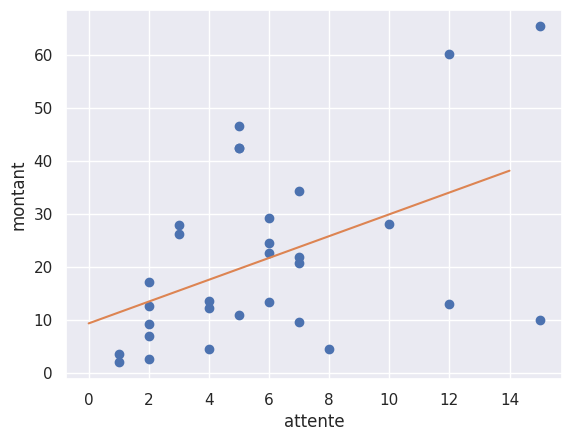

In [193]:
plt.plot(courses.attente, courses.montant, 'o')
plt.plot(np.arange(15), [a*x+b for x in np.arange(15)])
plt.xlabel('attente')
plt.ylabel('montant')
plt.show()

ANOVA

In [194]:
operationsC = operations.loc[operations['montant'] > -2000].copy()
print(operationsC.shape)
print(operationsC['montant'].min())

(306, 6)
-602.27


In [195]:
X = 'categ'
Y = 'montant'

# filtrer pour garder uniquement les lignes de dépenses
sousEchantillon = operationsC[operationsC['montant'] < 0].dropna(subset=[X]).copy()

# passer le montant des dépenses du négatif au positif
sousEchantillon['montant'] = -sousEchantillon['montant']

# on écarte les outliers, dans ce cas les loyers
sousEchantillon = sousEchantillon[sousEchantillon['categ'] != 'LOYER']

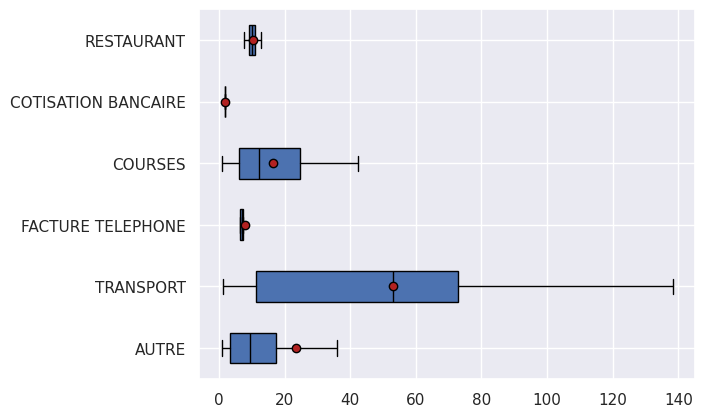

In [196]:
modalites = sousEchantillon[X].unique()
groupes = []

for m in modalites:
  montantM = sousEchantillon[sousEchantillon[X]==m][Y]
  groupes.append(montantM)

medianprops = {'color' : 'black'}
meanprops = {'marker': 'o', 'markeredgecolor': 'black', 'markerfacecolor': 'firebrick'}

plt.boxplot(groupes, tick_labels=modalites, showfliers=False, medianprops=medianprops, vert=False, patch_artist=True, showmeans=True, meanprops=meanprops)
plt.show()

In [197]:
X = 'categ'
Y = 'montant'

sousEchantillon = operationsC[operationsC['montant'] < 0].dropna(subset=[X]).copy()
sousEchantillon = sousEchantillon[sousEchantillon['categ'] != 'LOYER']
sousEchantillon['montant'] = -sousEchantillon['montant']


def etaSquared(x, y):
  moyenneY = y.mean()
  classes = []
  for classe in x.unique():
    yiClasse = y[x==classe]
    classes.append({'ni': len(yiClasse), 'moyenneClasse': yiClasse.mean()})
  SCT = sum([(yj-moyenneY)**2 for yj in y])
  SCE = sum([c['ni']*(c['moyenneClasse']-moyenneY)**2 for c in classes])
  return SCE/SCT

etaSquared(sousEchantillon[X], sousEchantillon[Y])

np.float64(0.027987626321194222)